In [136]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [114]:
test1 = '02062.png'
test2 = '02061.png'

In [115]:
sift = cv2.SIFT_create()

In [116]:
img1 = cv2.imread(test1)
img2 = cv2.imread(test2)
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

In [117]:
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

In [118]:
matches = bf.knnMatch(des1, des2, k=2)

In [119]:
good_matches = []
for m, n in  matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

In [120]:
type(good_matches[50])

cv2.DMatch

In [121]:
match_img = cv2.drawMatches(img1, kp1, img2, kp2, good_matches[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

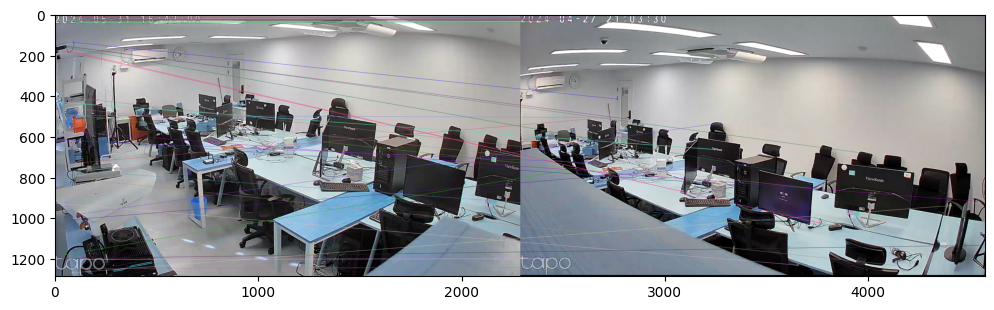

In [122]:
plt.figure(figsize=(12,6))
plt.imshow(match_img)
plt.show()

In [123]:
if len(good_matches) > 10:
    src_pts = numpy.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1,1,2)
    dst_pts = numpy.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1,1,2)

    matrix, mask = cv2.estimateAffinePartial2D(src_pts, dst_pts)

    if matrix is not None:
        transformed_img1 = cv2.warpAffine(img1, matrix, (img2.shape[1], img2.shape[0]))

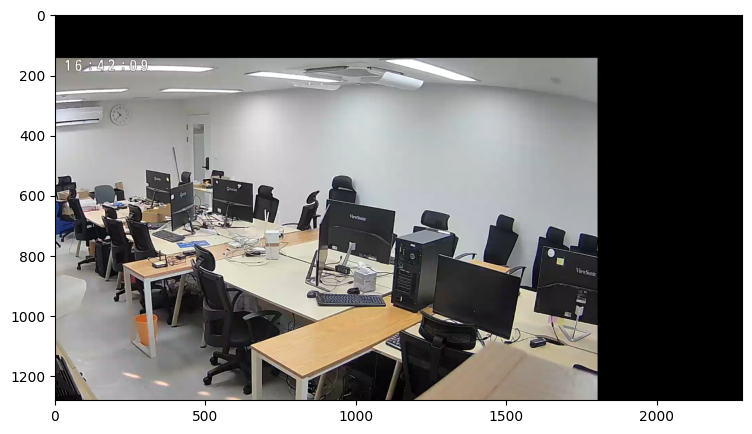

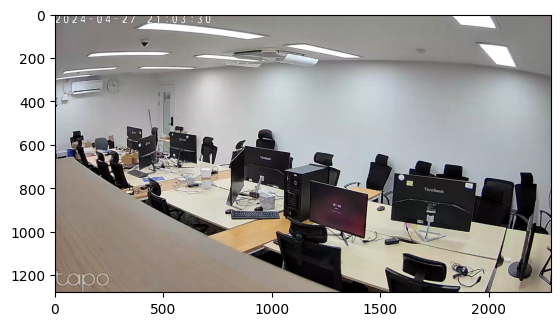

In [124]:
if transformed_img1 is not None:
    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(transformed_img1, cv2.COLOR_BGR2RGB))
    plt.show()
    plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    plt.show()

In [110]:
stitcher = cv2.Stitcher_create()
status, stitch_img = stitcher.stitch([transformed_img1, img2])

In [111]:
status == cv2.Stitcher_OK

False

In [84]:
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

In [85]:
height, width, _ = img2.shape

In [86]:
result = cv2.warpPerspective(img1, H, (width * 2, height))

In [87]:
result[0:height, 0:width] = img2

In [165]:
stitch_img = result

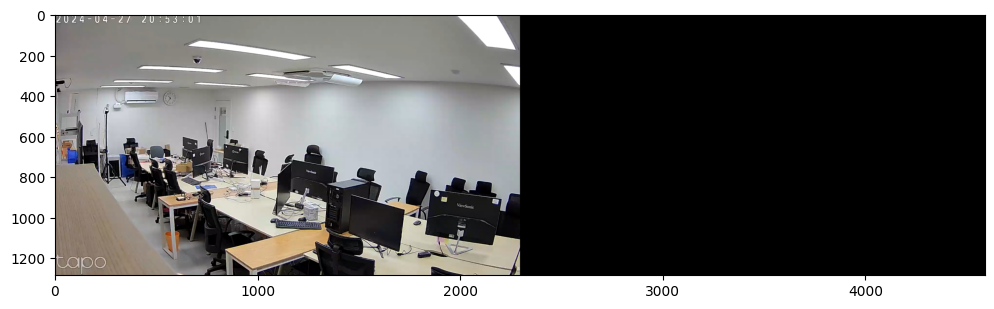

In [89]:
if stitch_img is not None:
    plt.figure(figsize=(12,6))
    plt.imshow(cv2.cvtColor(stitch_img, cv2.COLOR_BGR2RGB))
    plt.show()

In [25]:
left_img = cv2.imread("02101.png")  # 왼쪽 카메라 이미지
right_img = cv2.imread("02102.png")  # 오른쪽 카메라 이미지
# left_img = cv2.imread("test1.png")  # 왼쪽 카메라 이미지
# right_img = cv2.imread("test2.png")  # 오른쪽 카메라 이미지
# 이미지 크기 조정 (테스트 용도)
left_img = cv2.resize(left_img, (1920, 1080))
right_img = cv2.resize(right_img, (1920, 1080))

# OpenCV의 스티처(Stitcher) 사용 (자동 이미지 합성)
stitcher = cv2.Stitcher_create()
status, result = stitcher.stitch([left_img, right_img])
if status == cv2.Stitcher_OK:
    plt.figure(figsize=(12,6))
    plt.imshow(cv2.cvtColor(stitch_img, cv2.COLOR_BGR2RGB))
    plt.show()

In [26]:
sift = cv2.SIFT_create()
keypoints1, descriptors1 = sift.detectAndCompute(left_img, None)
keypoints2, descriptors2 = sift.detectAndCompute(right_img, None)

# FLANN 기반 특징점 매칭
flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
matches = flann.knnMatch(descriptors1, descriptors2, k=2)

# 좋은 매칭점 선택
good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]

In [27]:
if len(good_matches) > 10:
    src_pts = np.float32([keypoints1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([keypoints2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    # Homography 행렬 계산 (RANSAC 사용)
    H, mask = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC, 5.0)

    # 투영 변환 적용 (Perspective Transform)
    height, width, _ = left_img.shape
    transformed_img = cv2.warpPerspective(right_img, H, (width * 2, height * 2))

    transformed_img[0:height, 0:width] = left_img

    # alpha = np.linspace(1, 0, width).reshape(1, width)  # 좌 → 우 그라데이션
    # alpha = np.tile(alpha, (height, 1))  # 높이 방향으로 확장
    # alpha = np.expand_dims(alpha, axis=2)  # (height, width, 1)로 변환하여 RGB와 일치
    # alpha = np.repeat(alpha, 3, axis=2)  # (height, width, 3)으로 RGB 채널 복제

    # # 블렌딩 적용
    # blended_region = (left_img * alpha + transformed_img[:height, :width] * (1 - alpha)).astype(np.uint8)
    # transformed_img[0:height, 0:width] = blended_region  # 블렌딩된 부분 적용

1080 1920


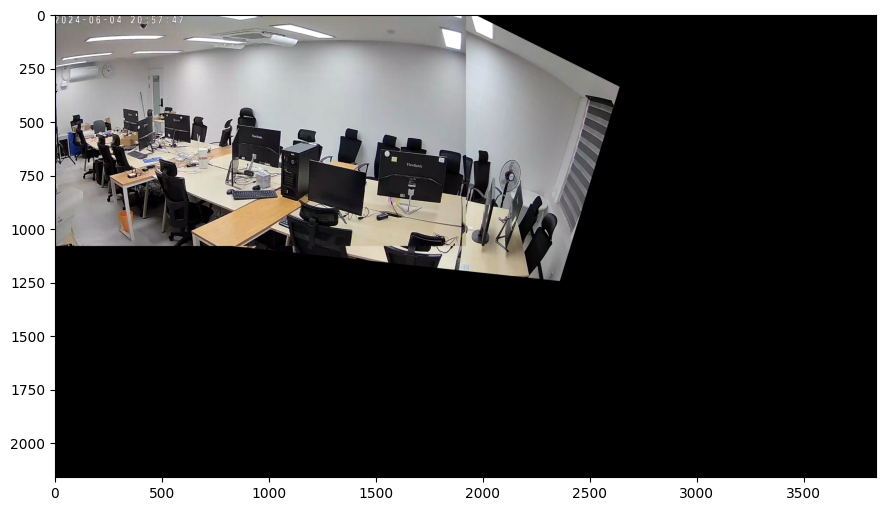

In [28]:
print(height, width)
plt.figure(figsize=(12,6))
plt.imshow(cv2.cvtColor(transformed_img, cv2.COLOR_BGR2RGB))

In [1]:
import cv2
import numpy as np
import time

import matplotlib.pyplot as plt

In [20]:

rtsp_url_1 = "rtsp://<USER>:<PASSWORD>@<CAMERA_IP_2>:554/stream1"
rtsp_url_2 = "rtsp://<USER>:<PASSWORD>@<CAMERA_IP>:1554/stream1"
rtsp_url_3 = "rtsp://<USER>:<PASSWORD>@<CAMERA_IP>:2554/stream1"
cap1 = cv2.VideoCapture(rtsp_url_1)
cap2 = cv2.VideoCapture(rtsp_url_2)
cap3 = cv2.VideoCapture(rtsp_url_3)
output_video_path = "stitched_video.mp4"
fps = cap1.get(cv2.CAP_PROP_FPS)
duration = 20
total_frames = fps * duration 

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()


plt.figure(figsize=(12,6))
plt.imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))

cap1.release()
cap2.release()
cap3.release()

[ WARN:0@3616.344] global cap_ffmpeg_impl.hpp:453 _opencv_ffmpeg_interrupt_callback Stream timeout triggered after 30053.455015 ms


error: OpenCV(4.10.0) /io/opencv/modules/imgproc/src/color.cpp:196: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


<Figure size 1200x600 with 0 Axes>

In [17]:
cap1 = cv2.VideoCapture(rtsp_url_1)
cap2 = cv2.VideoCapture(rtsp_url_2)
output_video_path = "stitched_video.mp4"
fps = cap1.get(cv2.CAP_PROP_FPS)
duration = 240
total_frames = fps * duration 

# 첫 번째 프레임 크기 확인
ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

if not (ret1 and ret2):
    print('exit')
    cap1.release()
    cap2.release()
    exit()

height, width = min(frame1.shape[:2], frame2.shape[:2])
frame1 = cv2.resize(frame1, (width, height))
frame2 = cv2.resize(frame2, (width, height))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))
sift = cv2.SIFT_create()
start_time = time.time()

while int(time.time() - start_time) < duration:
    ret1, frame1 = cap1.read()
    ret2, frame2 = cap2.read()

    if not (ret1 and ret2):
        print("error.")
        break

    frame1 = cv2.resize(frame1, (width, height))
    frame2 = cv2.resize(frame2, (width, height))

    keypoints1, descriptors1 = sift.detectAndCompute(frame1, None)
    keypoints2, descriptors2 = sift.detectAndCompute(frame2, None)

    flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
    matches = flann.knnMatch(descriptors1, descriptors2, k=2)

    good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]

    if len(good_matches) > 10:
        src_pts = np.float32([keypoints1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([keypoints2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        H, mask = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC, 5.0)

        transformed_img = cv2.warpPerspective(frame2, H, (width * 2, height * 2))

        transformed_img[0:height, 0:width] = frame1

        # gray = cv2.cvtColor(transformed_img, cv2.COLOR_BGR2GRAY)
        # _, mask = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)

        # contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # x, y, w, h = cv2.boundingRect(contours[0])

        # stitched_cropped = transformed_img[y:y+h, x:x+w]

        stitched_cropped = cv2.resize(transformed_img, (width, height))
        out.write(stitched_cropped) 

        # plt.figure(figsize=(12,6))
        # plt.imshow(cv2.cvtColor(stitched_cropped, cv2.COLOR_BGR2RGB))
        # break
    else:
        print('bad')
cap1.release()
cap2.release()
out.release()

[rtsp @ 0x55a5a4d4e7c0] RTP: PT=60: bad cseq e31e expected=d450
[rtsp @ 0x55a5a4d4e7c0] RTP: PT=60: bad cseq eff6 expected=e336
[rtsp @ 0x55a5a4d4e7c0] RTP: PT=08: bad cseq 92b8 expected=8663
[h264 @ 0x55a5a7a65d40] left block unavailable for requested intra mode
[h264 @ 0x55a5a7a65d40] error while decoding MB 0 64, bytestream 32375


In [19]:

cap1.release()
cap2.release()
cap3.release()

In [14]:
cap1 = cv2.VideoCapture(rtsp_url_1)
cap2 = cv2.VideoCapture(rtsp_url_2)
output_video_path = "test.mp4"
fps1 = cap1.get(cv2.CAP_PROP_FPS)
fps2 = cap1.get(cv2.CAP_PROP_FPS)

fps = min(fps1,fps2) if fps1 > 0 and fps2 > 0 else 15
frame_time = 1 / fps
duration = 20
total_frames = fps * duration 

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

if not (ret1 and ret2):
    print('exit')
    cap1.release()
    cap2.release()
    exit()

height, width = min(frame1.shape[:2], frame2.shape[:2])
frame1 = cv2.resize(frame1, (width, height))
frame2 = cv2.resize(frame2, (width, height))
sift = cv2.SIFT_create()


keypoints1, descriptors1 = sift.detectAndCompute(frame1, None)
keypoints2, descriptors2 = sift.detectAndCompute(frame2, None)

flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
matches = flann.knnMatch(descriptors1, descriptors2, k=2)

good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]

if len(good_matches) > 10:
    src_pts = np.float32([keypoints1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([keypoints2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC, 5.0)
else:
    cap1.release()
    cap2.release()
    out.release()
    print('bad')

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))

start_time = time.time()
frame_count = 0

while int(time.time() - start_time) < duration:
    frame_start = time.time() 
    timestamp1 = time.time()
    ret1, frame1 = cap1.read()
    
    time.sleep(frame_time / 2)
    timestamp2 = time.time()
    ret2, frame2 = cap2.read()

    if not (ret1 and ret2):
        print("error.")
        break
    time_diff = abs(timestamp2 - timestamp1)
    print(f"🔹 카메라 프레임 시간 차이: {time_diff:.4f} 초")
    
    while abs(timestamp2 - timestamp1) > frame_time * 0.8:
        print(abs(timestamp1 - timestamp2) , "/",  frame_time * 0.5)
        ret1, frame1 = cap2.read()
        timestamp1 = time.time()
        
    transformed_img = cv2.warpPerspective(frame2, H, (width * 2, height * 2))
    
    transformed_img[0:height, 0:width] = frame1

    # gray = cv2.cvtColor(transformed_img, cv2.COLOR_BGR2GRAY)
    # _, mask = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)

    # contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # x, y, w, h = cv2.boundingRect(contours[0])

    # stitched_cropped = transformed_img[y:y+h, x:x+w]

    stitched_cropped = cv2.resize(transformed_img, (width, height))
    out.write(stitched_cropped) 

    # plt.figure(figsize=(12,6))
    # plt.imshow(cv2.cvtColor(stitched_cropped, cv2.COLOR_BGR2RGB))
    # break
cap1.release()
cap2.release()
out.release()

🔹 카메라 프레임 시간 차이: 0.0359 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0357 초
🔹 카메라 프레임 시간 차이: 0.0355 초
🔹 카메라 프레임 시간 차이: 0.0355 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0355 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0355 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0353 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0353 초
🔹 카메라 프레임 시간 차이: 0.0353 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0357 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0350 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0354 초
🔹 카메라 프레임 시간 차이: 0.0351 초
🔹 카메라 프레임 시간 차이: 0.0353 초
🔹 카메라 프레임 시간 차이: 0.0352 초
🔹 카메라 프레임 시간 차이: 0.0350 초
🔹 카메라 프레임 시간 차이: 0.0353 초
🔹 카메라 프레임 시간

In [72]:
import torch
import torchvision.transforms as transforms
from PIL import Image

In [99]:
class HomographyNet(torch.nn.Module):
    def __init__(self):
        super(HomographyNet, self).__init__()
        self.resnet = torch.nn.Sequential(
            torch.nn.Conv2d(8, 64, kernel_size=3, stride=1, padding=1),
            torch.nn.ReLU(),
            torch.nn.Flatten(),
            torch.nn.Linear(64 * 256 * 256, 8)
        )

    def forward(self, img1, img2):
        x = torch.cat((img1, img2), dim=1)
        return self.resnet(x)

In [100]:
model = HomographyNet()
model.eval()

HomographyNet(
  (resnet): Sequential(
    (0): Conv2d(8, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Flatten(start_dim=1, end_dim=-1)
    (3): Linear(in_features=4194304, out_features=8, bias=True)
  )
)

In [101]:
transform = transforms.Compose([transforms.Resize((256, 256)), transforms.ToTensor()])

In [102]:
def predict_homography(img1, img2):
    img1, img2 = transform(img1).unsqueeze(0), transform(img2).unsqueeze(0)
    with torch.no_grad():
        return model(img1, img2)

In [111]:
image1 = Image.open("02101.png")
image2 = Image.open("02102.png")
homography_result = predict_homography(image1, image2)

In [112]:
H_matrix = torch.cat([homography_result, torch.tensor([[1.0]])], dim=1).reshape(3, 3)

In [113]:
H_matrix_np = H_matrix.numpy()
image1_cv = np.array(image1)
image2_cv = np.array(image2)
height, width = image1_cv.shape[:2]
image2_warped = cv2.warpPerspective(image2_cv, H_matrix_np, (width, height))

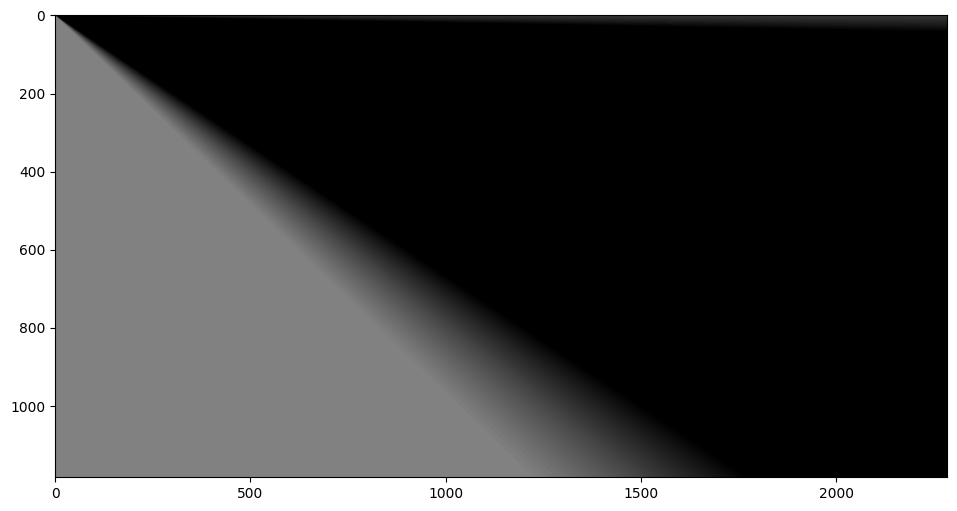

In [114]:
plt.figure(figsize=(12,6))
plt.imshow(cv2.cvtColor(image2_warped, cv2.COLOR_BGR2RGB))

In [93]:
height, width

(1183, 2285)